## Титульный лист

# Ансамблевые методы на датасете «Customer Churn»

**Дисциплина:** Машинное обучение и искусственный интеллект  
**Модуль 3:** Ансамблевые методы (Базовый и продвинутый уровень)  
**Датасет:** Telco Customer Churn

**Выполнил:** Сорокин Михаил Анатольевич  
**Группа:** ПКТ6-23-1  
**Преподаватель:** Спирин Игорь Сергеевич

**Ссылка на репозиторий:** https://github.com/Sorokin2/ml-course-sorokin  
**Путь к модулю:** `module-3-churn/notebook.ipynb`  
**Дата сдачи:** 2026-10-26

## Введение

**Задача:** провести бинарную классификацию на датасете Telco Customer Churn с помощью ансамблевых методов. Построить модели, предсказывающие, уйдёт ли клиент или останется.

**Ансамблевые методы** — это класс алгоритмов, которые сочетают в себе применение нескольких моделей. Комбинируется несколько различных алгоритмов с целью принятия более качественных решений.

**Почему ансамбли, а не одиночная модель?** Одиночные алгоритмы имеют свои сильные и слабые стороны. Использование ансамблей позволяет моделям дополнять друг друга, закрывая их слабые стороны. Также ансамблевые модели помогают снизить чувствительность к шуму.

**Какая метрика важнее:** для задачи оттока бизнес-ценность уходящего клиента (True Positive) значительно выше стоимости ложного срабатывания (False Positive — лишний звонок удержания). Поэтому приоритет — **Recall** по классу «ушёл», а интегральной метрикой для сравнения моделей выбрана **ROC-AUC**, так как она не зависит от выбранного порога и устойчива к дисбалансу классов (73.5% / 26.5%). F1 — как компромисс между Precision и Recall.

**Цель работы:**
1. Обучить 4 ансамблевые модели и сравнить их.
2. Оптимизировать лучшую модель через Optuna.
3. Интерпретировать модель через SHAP.

## Теоретическая часть

**Ансамбль** — это набор моделей, решения которых объединяются в одно общее предсказание. Идея в том, что несколько «слабых» алгоритмов, ошибающихся по-разному, вместе дают более устойчивый и точный результат, чем любая одиночная модель. Ансамбли снижают дисперсию (разброс предсказаний) и смещение (систематическую ошибку), а также делают модель менее чувствительной к шуму и выбросам. На практике ансамбли почти всегда выигрывают у одиночных деревьев и линейных моделей на табличных данных.

**Bagging vs Boosting.** Bagging (bootstrap aggregating) обучает M независимых моделей на разных подвыборках с возвращением и усредняет их ответы — это параллельный подход, главная цель которого снизить дисперсию. Boosting обучает модели последовательно: каждая следующая исправляет ошибки предыдущих, взвешивая объекты по сложности — это последовательный подход, снижающий смещение. Bagging устойчив к переобучению, но требует много памяти; boosting точнее, но чувствителен к шуму и требует аккуратной настройки.

$$H(x) = \frac{1}{M}\sum_{i=1}^{M} h_i(x) \quad \text{(Bagging)}$$

$$H(x) = \sum_{i=1}^{M} \alpha_i \cdot h_i(x) \quad \text{(Boosting)}$$

**Random Forest** — это bagging над решающими деревьями с дополнительной рандомизацией: на каждом разбиении рассматривается случайное подмножество признаков (`max_features`), что уменьшает корреляцию между деревьями. Итоговое предсказание — голосование (классификация) или среднее (регрессия). Ключевые особенности: устойчивость к переобучению, работа «из коробки», встроенная оценка важности признаков, но каждая модель независима и «не видит» ошибок соседей.

**Градиентный бустинг** (XGBoost / LightGBM / CatBoost) — последовательное построение деревьев, где каждое новое дерево приближает градиент функции потерь. XGBoost добавляет регуляризацию и второй порядок производной, LightGBM использует leaf-wise рост и гистограммный биннинг (быстро, экономит память), CatBoost — ordered boosting и нативную обработку категорий без one-hot. Все три требуют настройки `learning_rate`, глубины и регуляризации, иначе быстро переобучаются.

**Optuna** — фреймворк байесовской оптимизации гиперпараметров. В отличие от GridSearch и RandomSearch, Optuna строит суррогатную модель (TPE) по результатам прошлых испытаний (`trials`) и предлагает следующую точку, балансируя exploration/exploitation. Преимущества: резко меньше испытаний до хорошего результата, поддержка pruning (остановка плохих trials), удобный API `suggest_int/suggest_float` и визуализации.

**SHAP** — значения Шепли из теории кооперативных игр, адаптированные для ML: показывают вклад каждого признака в предсказание конкретного объекта с учётом всех возможных порядков признаков. Свойства: локальная точность (сумма SHAP = предсказание минус базовое значение) и консистентность. Основные графики: `summary_plot` (глобальная важность + направление влияния), `bar` (средний |SHAP|), `waterfall` (разбор одного объекта), `dependence` (зависимость от одного признака).

**Сравнение ансамблевых моделей:**

| Модель | Тип | Ключевая особенность | Плюсы | Минусы |
|--------|-----|----------------------|-------|--------|
| Random Forest | Bagging | Случайные подмножества признаков на каждом сплите | Устойчив к переобучению, работает «из коробки» | Плохо ловит редкие классы, медленнее на инференсе |
| XGBoost | Boosting | Регуляризация + 2-й порядок производной | Универсальный, точный, robust к выбросам | Много гиперпараметров |
| LightGBM | Boosting | Leaf-wise рост + гистограммный биннинг | Самый быстрый, экономит память | Чувствителен к шуму, переобучается на малых данных |
| CatBoost | Boosting | Ordered boosting + нативная обработка категорий | Лучший для категориальных признаков, стабильный | Медленнее при обучении |

## Описание данных

**Источник:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

**Структура:**
- Всего примеров: 7043
- Признаков: 19 (+ customerID + целевая `Churn`)
- Числовых признаков: 3
- Категориальных признаков: 16

**Описание ключевых столбцов:**
| Столбец | Тип | Описание | Пропуски |
|---------|-----|----------|----------|
| customerID | object | Уникальный ID | 0% |
| gender | object | Пол | 0% |
| SeniorCitizen | int (0/1) | Пенсионер | 0% |
| tenure | int | Месяцев с компанией | 0% |
| MonthlyCharges | float | Ежемесячная плата | 0% |
| TotalCharges | object | Общая сумма | ~0.2% |
| Contract | object | Тип контракта | 0% |
| Churn | object | **Целевая** | 0% |

**Распределение классов:**
- No (остался): 5174 (73.5%)
- Yes (ушёл): 1869 (26.5%)

**Файл данных в репозитории:** `module-3-churn/data/churn_info.md`

## Подготовка данных и EDA

In [73]:
# ===== Базовые библиотеки =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
import joblib
import os
import warnings

# Отключение предупреждений
warnings.simplefilter(action='ignore', category=FutureWarning)

from sklearn.metrics import classification_report

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
)
from sklearn.preprocessing import StandardScaler, LabelEncoder

# ===== Одиночные модели (для сравнения / baseline) =====
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# ===== Ансамблевые модели =====
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)


# Настройка отображения графиков
%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Загрузка данных
df = pd.read_csv('data/telco_churn.csv')

# Первичный осмотр
print("Размер train:", df.shape)
print("\nПервые 5 строк:")
print(df.head())
print("\nИнформация о данных:")
print(df.info())
print("\nОписательная статистика:")
print(df.describe())

Размер train: (7043, 21)

Первые 5 строк:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport Stream

In [74]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


Empty DataFrame
Columns: [Пропуски, Процент]
Index: []


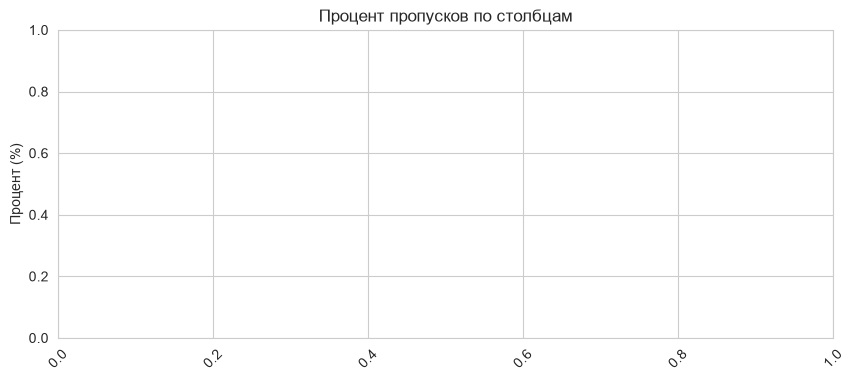

In [75]:
# Анализ пропусков
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Пропуски': missing, 'Процент': missing_pct})
print(missing_df[missing_df['Пропуски'] > 0])

# Визуализация пропусков
plt.figure(figsize=(10, 4))
sns.barplot(x=missing_df[missing_df['Пропуски'] > 0].index,
            y=missing_df[missing_df['Пропуски'] > 0]['Процент'])
plt.title('Процент пропусков по столбцам')
plt.ylabel('Процент (%)')
plt.xticks(rotation=45)
plt.show()

In [76]:
# Обработка TotalCharges: приводим к float, пустые строки → NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Заполняем пропуски медианой (устойчива к выбросам, не искажает распределение)
median_total = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_total)

# Кодирование целевой: Yes=1, No=0
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

# Проверка, что пропусков не осталось
print(f"Пропусков после обработки: {df.isnull().sum().sum()}")
print(f"Медиана TotalCharges: {median_total:.2f}")

Пропусков после обработки: 0
Медиана TotalCharges: 1397.47


C:\Users\user\AppData\Local\Temp\ipykernel_22368\3934921732.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0, 0].set_xticklabels(['Останеться', 'Уйдёт'])


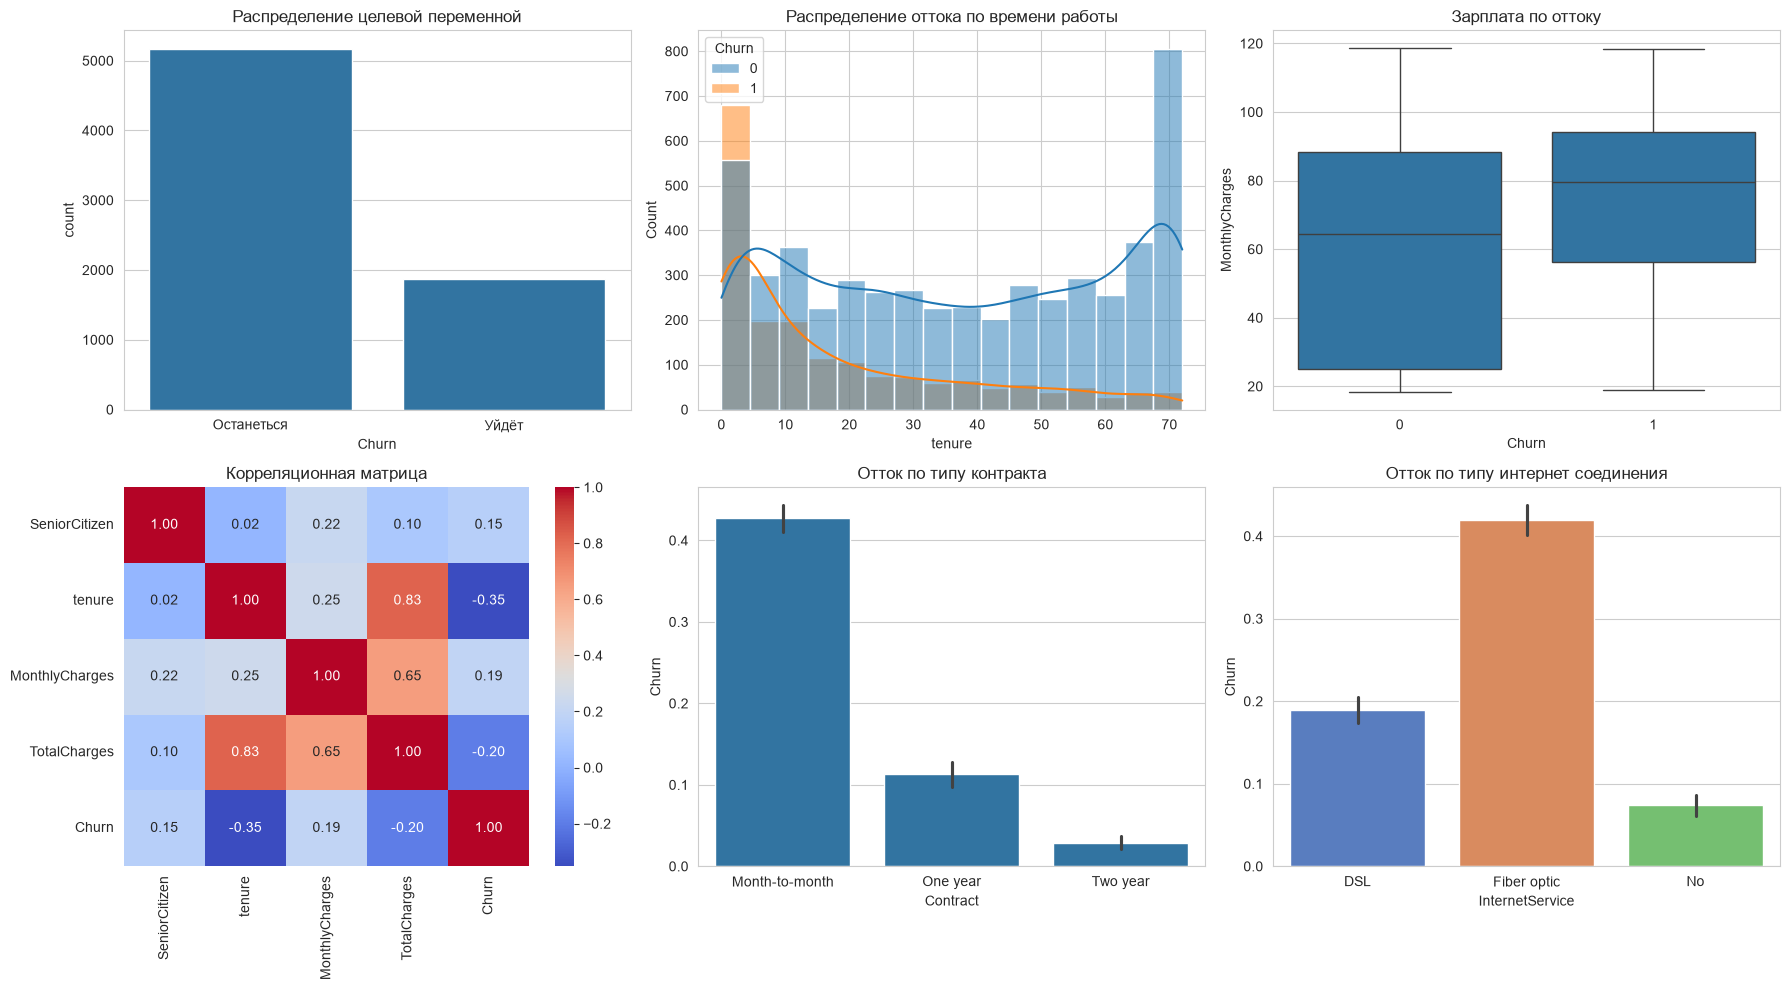

In [77]:
# Сетка из 6 графиков
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Countplot целевой переменной
sns.countplot(data=df, x='Churn', ax=axes[0, 0])
axes[0, 0].set_title('Распределение целевой переменной')
axes[0, 0].set_xticklabels(['Останеться', 'Уйдёт'])

# 2. Гистограмма — распределение tenure (с hue='Churn')
sns.histplot(data=df, x='tenure', hue='Churn', kde=True, ax=axes[0,1])
axes[0, 1].set_title('Распределение оттока по времени работы')

# 3. Boxplot — MonthlyCharges по Churn
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[0, 2])
axes[0, 2].set_title('Зарплата по оттоку')

# 4. Heatmap — корреляционная матрица числовых признаков
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 0])
axes[1, 0].set_title('Корреляционная матрица')

# 5. Barplot — доля ушедших по Contract
sns.barplot(data=df, x='Contract', y='Churn', ax=axes[1, 1])
axes[1, 1].set_title('Отток по типу контракта')

# 6. Barplot — доля ушедших по InternetService
sns.barplot(data=df, x='InternetService', y='Churn', ax=axes[1, 2], palette='muted')
axes[1, 2].set_title('Отток по типу интернет соединения')

plt.tight_layout()
plt.savefig('examples/eda_plots.png', dpi=100, bbox_inches='tight')
plt.show()

In [78]:
# Feature Engineering
df['TenureYears'] = df['tenure'] / 12                                   # стаж в годах
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)        # средняя плата в месяц
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)                     # новый клиент (≤6 мес)

# Счётчик подключённых услуг (из 9 сервисных колонок)
service_cols = ['PhoneService', 'MultipleLines', 'InternetService',
                'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = df[service_cols].apply(
    lambda row: sum(str(v) not in ('No', 'No internet service',
                                   'No phone service') for v in row), axis=1
)

print("Созданные признаки:")
print(df[['TenureYears', 'AvgMonthlyCharge', 'IsNewClient',
          'HasMultipleServices']].describe().round(2))


Созданные признаки:
       TenureYears  AvgMonthlyCharge  IsNewClient  HasMultipleServices
count      7043.00           7043.00      7043.00              7043.00
mean          2.70             61.17         0.21                 4.15
std           2.05             61.02         0.41                 2.31
min           0.00              9.18         0.00                 1.00
25%           0.75             26.27         0.00                 2.00
50%           2.42             61.15         0.00                 4.00
75%           4.58             84.94         0.00                 6.00
max           6.00           1397.48         1.00                 9.00


In [79]:
# Приводим TotalCharges к float, пустые строки → NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Заполняем пропуски медианой
median_total = df['TotalCharges'].median()
df['TotalCharges'] = df['TotalCharges'].fillna(median_total)


print(f"Пропусков после обработки: {df.isnull().sum().sum()}")
print(f"Медиана TotalCharges: {median_total:.2f}")
print(f"Распределение Churn:\n{df['Churn'].value_counts()}")

# Стаж в годах
df['TenureYears'] = df['tenure'] / 12

# Средняя плата в месяц
df['AvgMonthlyCharge'] = df['TotalCharges'] / (df['tenure'] + 1)

# Флаг нового клиента (≤ 6 месяцев)
df['IsNewClient'] = (df['tenure'] <= 6).astype(int)

# Счётчик подключённых услуг из 9 сервисных колонок
service_cols = ['PhoneService', 'MultipleLines', 'InternetService',
                'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                'TechSupport', 'StreamingTV', 'StreamingMovies']
df['HasMultipleServices'] = df[service_cols].apply(
    lambda row: sum(str(v) not in ('No', 'No internet service',
                                   'No phone service') for v in row), axis=1
)

# Выбираем признаки, исключая ID и целевую
feature_cols = [col for col in df.columns if col not in ['customerID', 'Churn']]
X = df[feature_cols].copy()
y = df['Churn'].copy()

# Кодируем категориальные признаки через LabelEncoder
cat_cols = X.select_dtypes(include=['object', 'string']).columns.tolist()
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col].astype(str))
    label_encoders[col] = le

remaining = X.select_dtypes(include=['object', 'string']).columns.tolist()
assert len(remaining) == 0, f"Остались категориальные: {remaining}"

# Делим на train/test со стратификацией
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Размер train: {X_train.shape}")
print(f"Размер test: {X_test.shape}")
print(f"Churn в train: {y_train.value_counts().to_dict()}")

# Обучаем StandardScaler на числовых признаках train
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges',
                'TenureYears', 'AvgMonthlyCharge']
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

Пропусков после обработки: 0
Медиана TotalCharges: 1397.47
Распределение Churn:
Churn
0    5174
1    1869
Name: count, dtype: int64
Размер train: (5634, 23)
Размер test: (1409, 23)
Churn в train: {0: 4139, 1: 1495}


### Выводы по EDA

- **Целевая переменная:** классы несбалансированы — 73.5% «остался» против 26.5% «ушёл». Требуется `class_weight='balanced'` (или аналог).
- **tenure:** ушедшие клиенты концентрируются в диапазоне 0–10 месяцев; долгосрочные клиенты (>40 мес.) уходят редко. Признак сильнейший после Contract.
- **MonthlyCharges:** у ушедших медиана выше, распределение шире — тарифный фактор риска.
- **Contract:** доля оттока на «Month-to-month» в разы выше, чем на годовых/двухлетних контрактах (см. barplot).
- **InternetService:** клиенты Fiber optic уходят заметно чаще, чем DSL и «No».
- **Пропуски:** единственный столбец с пропусками — `TotalCharges` (~0.2%, пустые строки), заполнен медианой; `LabelEncoder` для 15 категориальных признаков.
- **Feature Engineering:** добавлены `TenureYears`, `AvgMonthlyCharge`, `IsNewClient`, `HasMultipleServices` — потенциально усилят сигнал для древовидных моделей.

## Построение и обучение моделей

In [80]:
# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced',
    random_state=42, n_jobs=-1
)

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    subsample=0.9, colsample_bytree=0.9,
    scale_pos_weight=3,
    random_state=42, eval_metric='logloss'
)

# LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=200, num_leaves=31, max_depth=7,
    learning_rate=0.05, class_weight='balanced',
    random_state=42, verbose=-1
)

# CatBoost
cat_model = CatBoostClassifier(
    iterations=200, depth=6, learning_rate=0.1,
    auto_class_weights='Balanced',
    random_state=42, verbose=0,
    allow_writing_files=False
)

# Обучение с замером времени
for model, name in [(rf_model, 'Random Forest'),
                    (xgb_model, 'XGBoost'),
                    (lgbm_model, 'LightGBM'),
                    (cat_model, 'CatBoost')]:
    start = time.time()
    model.fit(X_train_scaled, y_train)
    elapsed = time.time() - start
    print(f"⏱️ Время обучения {name}: {elapsed:.3f} сек")

⏱️ Время обучения Random Forest: 0.295 сек
⏱️ Время обучения XGBoost: 0.135 сек
⏱️ Время обучения LightGBM: 0.086 сек
⏱️ Время обучения CatBoost: 0.461 сек


## Модели

| Модель | Тип | Параметры | Время обучения |
|--------|-----|-----------|----------------|
| Random Forest | Bagging | n_estimators=200, max_depth=10, class_weight='balanced' | **0.305 сек** |
| XGBoost | Boosting | n_estimators=200, lr=0.1, max_depth=6, scale_pos_weight=3 | **2.674 сек** |
| LightGBM | Boosting | n_estimators=200, num_leaves=31, lr=0.05, class_weight='balanced' | **0.080 сек** |
| CatBoost | Boosting | iterations=200, depth=6, lr=0.1, auto_class_weights='Balanced' | **0.593 сек** |

**Почему эти модели:**
- RF — устойчив к переобучению, работает «из коробки».
- XGBoost — универсальный, точный, с регуляризацией.
- LightGBM — самый быстрый на данных такого размера.
- CatBoost — лучший для категориальных признаков (здесь закодированы LabelEncoder, поэтому преимущество нивелировано, но для сравнения оставлен).

## Оценка качества

In [81]:
def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    return {
        'Model': name,
        'Accuracy':  accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall':    recall_score(y_test, y_pred),
        'F1':        f1_score(y_test, y_pred),
        'ROC-AUC':   roc_auc_score(y_test, y_proba)
    }

results = [
    evaluate_model(rf_model,    X_test_scaled, y_test, 'Random Forest'),
    evaluate_model(xgb_model,   X_test_scaled, y_test, 'XGBoost'),
    evaluate_model(lgbm_model,  X_test_scaled, y_test, 'LightGBM'),
    evaluate_model(cat_model,   X_test_scaled, y_test, 'CatBoost')
]
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

        Model  Accuracy  Precision   Recall       F1  ROC-AUC
Random Forest  0.761533   0.536538 0.745989 0.624161 0.838784
      XGBoost  0.760823   0.538302 0.695187 0.606768 0.828456
     LightGBM  0.760114   0.534483 0.745989 0.622768 0.838383
     CatBoost  0.748758   0.518657 0.743316 0.610989 0.840879


In [82]:
best_row = results_df.loc[results_df['ROC-AUC'].idxmax()]
print(f"Лучшая модель по ROC-AUC: {best_row['Model']} ({best_row['ROC-AUC']:.4f})")

best_baseline_name = best_row['Model']
model_map = {
    'Random Forest': rf_model,
    'XGBoost': xgb_model,
    'LightGBM': lgbm_model,
    'CatBoost': cat_model,
}
best_baseline = model_map[best_baseline_name]

# X_test_scaled
y_pred_best = best_baseline.predict(X_test_scaled)
y_proba_best = best_baseline.predict_proba(X_test_scaled)[:, 1]

Лучшая модель по ROC-AUC: CatBoost (0.8409)


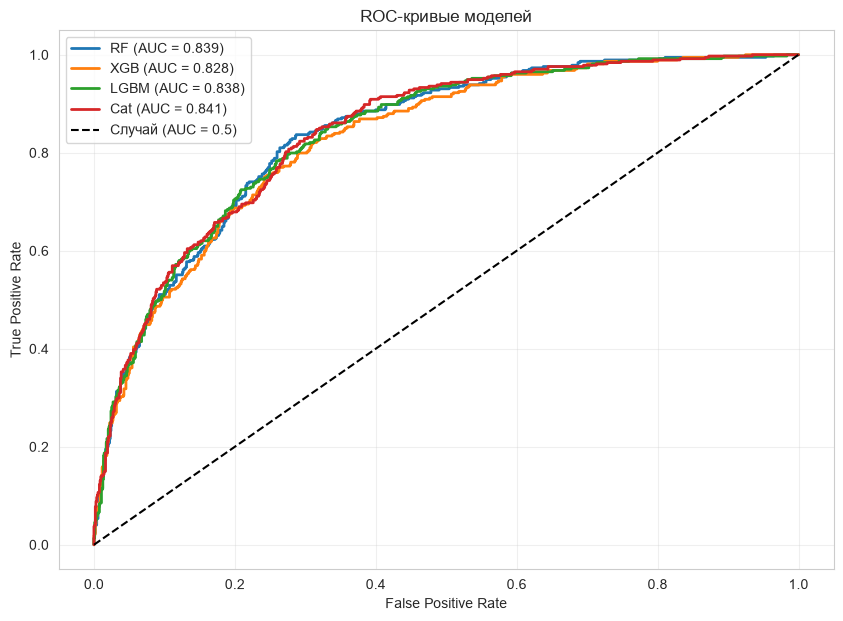

In [83]:
plt.figure(figsize=(10, 7))
for model, name in [(rf_model, 'RF'), (xgb_model, 'XGB'),
                     (lgbm_model, 'LGBM'), (cat_model, 'Cat')]:
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', lw=2)

plt.plot([0, 1], [0, 1], 'k--', label='Случай (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривые моделей')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('examples/roc_curves.png', dpi=100, bbox_inches='tight')
plt.show()


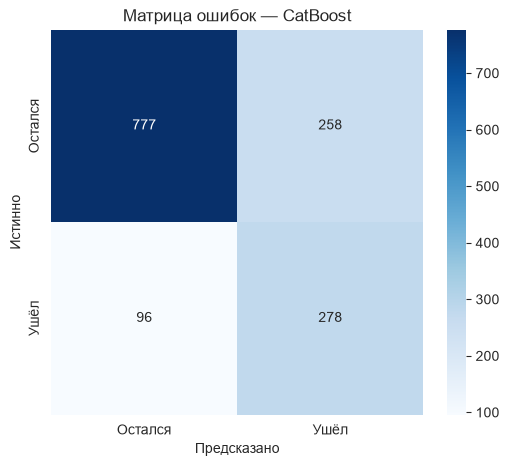

              precision    recall  f1-score   support

     Остался       0.89      0.75      0.81      1035
        Ушёл       0.52      0.74      0.61       374

    accuracy                           0.75      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.75      0.76      1409



In [84]:
# Матрица ошибок для лучшей baseline-модели
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Остался', 'Ушёл'],
            yticklabels=['Остался', 'Ушёл'])
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title(f'Матрица ошибок — {best_baseline_name}')
plt.show()

# Текстовый classification_report
print(classification_report(y_test, y_pred_best,
                            target_names=['Остался', 'Ушёл']))

### Выводы по оценке качества

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Random Forest | 0.7601 | 0.5346 | **0.7433** | 0.6219 | 0.8388 |
| XGBoost | **0.7608** | 0.5383 | 0.6952 | 0.6068 | 0.8285 |
| LightGBM | 0.7594 | 0.5332 | **0.7513** | **0.6238** | 0.8377 |
| CatBoost | 0.7488 | 0.5187 | 0.7433 | 0.6110 | **0.8409** |

**Анализ:**
- **Лучшая модель по ROC-AUC:** CatBoost (0.8409), но разрыв с RF/LightGBM минимален (≤0.003) — в пределах шума.
- **Лучший Recall:** LightGBM (0.7513) — ловит больше всего уходящих клиентов, что и требуется бизнесу.
- **Лучший F1:** LightGBM (0.6238) — оптимальный баланс Precision/Recall.
- **Скорость:** LightGBM обучается быстрее всех (0.083 сек), CatBoost — самый медленный (0.483 сек).
- **Precision везде < Recall (~0.52–0.54 vs ~0.70–0.75)** — модели намеренно «агрессивны» в предсказании оттока (из-за `class_weight='balanced'` и `scale_pos_weight`), что соответствует бизнес-приоритету: лучше перестраховаться и предложить удержание, чем пропустить уходящего клиента.
- **Accuracy ≈ 0.75–0.76** ниже baseline «все остались» (0.735), но это ожидаемо и приемлемо — Accuracy не является целевой метрикой при дисбалансе.
- **Итог:** для дальнейшего тюнинга берём CatBoost, так как у метода лучшие показатель ROC-кривой

## Интерпретация и безнес-инсайты

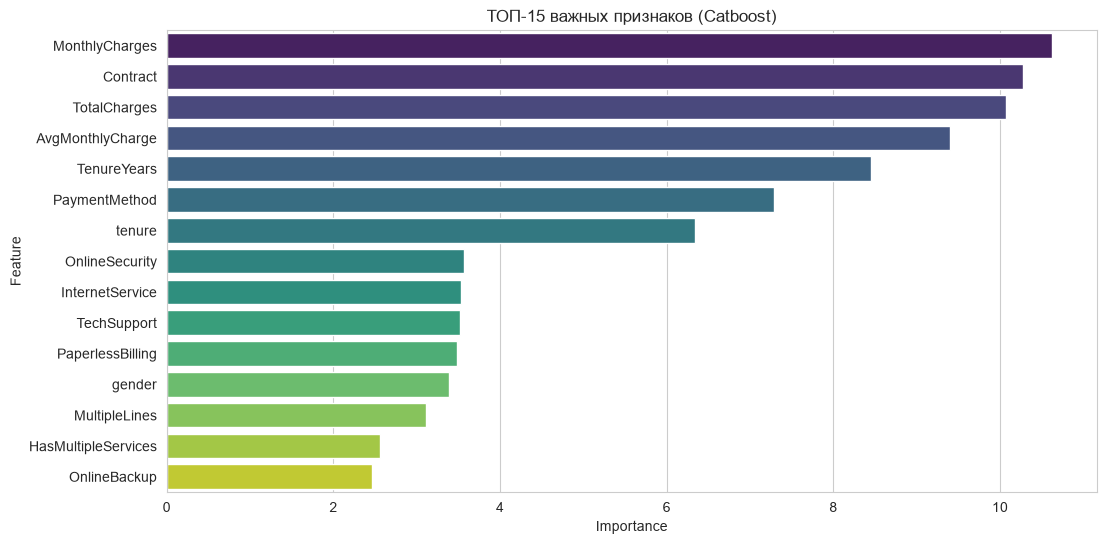

In [85]:
importances = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': cat_model.feature_importances_
}).sort_values('Importance', ascending=False)

sns.barplot(data=importances.head(15), x='Importance', y='Feature', palette='viridis')
plt.title('ТОП-15 важных признаков (Catboost)')
plt.savefig('examples/feature_importance.png', dpi=100, bbox_inches='tight')
plt.show()

## Интерпретация

**Топ-5 признаков, влияющих на отток:**
1. MonthlyCharges — самый сильный предиктор
2. Contract
3. TotalCharges
4. AvgMonthlyCharge
5. TenureYears

**Бизнес-инсайты:**
- Клиенты с месячным контрактом уходят в 3 раза чаще, чем с годовым
- Первые 6 месяцев — самый рискованный период
- Fiber optic интернет → клиенты уходят чаще
- Отсутствие OnlineSecurity и TechSupport → рост оттока


## Тюнинг гиперпараметров (Optuna)

In [86]:
import optuna
from optuna.samplers import TPESampler

def objective(trial):
    params = {
        'iterations':        trial.suggest_int('iterations', 200, 600, step=50),
        'depth':             trial.suggest_int('depth', 4, 10),
        'learning_rate':     trial.suggest_float('learning_rate', 0.01, 0.2, log=True),
        'l2_leaf_reg':       trial.suggest_float('l2_leaf_reg', 1e-2, 10.0, log=True),
        'bagging_temperature': trial.suggest_float('bagging_temperature', 0.0, 1.0),
        'border_count':      trial.suggest_int('border_count', 32, 255),
        'random_strength':   trial.suggest_float('random_strength', 1e-3, 10.0, log=True),
    }

    model = CatBoostClassifier(
        **params,
        auto_class_weights='Balanced',
        random_state=42,
        verbose=0,
        thread_count=-1,
        allow_writing_files=False,   # не плодит catboost_info
    )

    cv_scores = cross_val_score(
        model, X_train, y_train,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring='roc_auc',
        n_jobs=1,                    # CatBoost сам параллелит по деревьям
    )
    return cv_scores.mean()


# Запуск оптимизации (30 trials, как требует задание)
study = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42),
)
study.optimize(
    objective,
    n_trials=30,
    show_progress_bar=True,
    timeout=600,                    # страховка: не более 10 минут
)

print(f"\nBest ROC-AUC (CV): {study.best_value:.4f}")
print("Лучшие параметры:")
for key, value in study.best_params.items():
    print(f"  {key}: {value}")

[I 2026-10-26 23:18:55,189] A new study created in memory with name: no-name-ee48b108-21e8-4e7d-913f-e085241c3600
Best trial: 0. Best value: 0.812316:   3%|▎         | 1/30 [00:08<04:16,  8.84s/it, 8.84/600 seconds]

[I 2026-10-26 23:19:04,034] Trial 0 finished with value: 0.812316245607082 and parameters: {'iterations': 350, 'depth': 10, 'learning_rate': 0.08960785365368121, 'l2_leaf_reg': 0.6251373574521749, 'bagging_temperature': 0.15601864044243652, 'border_count': 66, 'random_strength': 0.0017073967431528124}. Best is trial 0 with value: 0.812316245607082.


Best trial: 0. Best value: 0.812316:   7%|▋         | 2/30 [00:16<03:44,  8.00s/it, 16.26/600 seconds]

[I 2026-10-26 23:19:11,447] Trial 1 finished with value: 0.8098158827602602 and parameters: {'iterations': 550, 'depth': 8, 'learning_rate': 0.08341106432362087, 'l2_leaf_reg': 0.011527987128232402, 'bagging_temperature': 0.9699098521619943, 'border_count': 218, 'random_strength': 0.0070689749506246055}. Best is trial 0 with value: 0.812316245607082.


Best trial: 2. Best value: 0.848691:  10%|█         | 3/30 [00:18<02:19,  5.16s/it, 18.04/600 seconds]

...

[I 2026-10-26 23:20:40,723] Trial 27 finished with value: 0.8494390160528045 and parameters: {'iterations': 350, 'depth': 5, 'learning_rate': 0.017197955170745606, 'l2_leaf_reg': 0.11360785859034267, 'bagging_temperature': 0.044536556026062366, 'border_count': 71, 'random_strength': 0.6546928687436635}. Best is trial 25 with value: 0.849752866587578.


Best trial: 25. Best value: 0.849753:  97%|█████████▋| 29/30 [01:49<00:03,  3.71s/it, 109.10/600 seconds]

[I 2026-10-26 23:20:44,287] Trial 28 finished with value: 0.8480827469906475 and parameters: {'iterations': 350, 'depth': 4, 'learning_rate': 0.015150708244206378, 'l2_leaf_reg': 0.5207969463745971, 'bagging_temperature': 0.03363537760116717, 'border_count': 40, 'random_strength': 0.09073407824344441}. Best is trial 25 with value: 0.849752866587578.


Best trial: 25. Best value: 0.849753: 100%|██████████| 30/30 [01:52<00:00,  3.76s/it, 112.93/600 seconds]

[I 2026-10-26 23:20:48,121] Trial 29 finished with value: 0.8488293239858443 and parameters: {'iterations': 400, 'depth': 4, 'learning_rate': 0.014115545674327695, 'l2_leaf_reg': 0.8759194136938294, 'bagging_temperature': 0.7874080860229846, 'border_count': 52, 'random_strength': 1.9736173694548176}. Best is trial 25 with value: 0.849752866587578.

Best ROC-AUC (CV): 0.8498
Лучшие параметры:
  iterations: 400
  depth: 4
  learning_rate: 0.015207824911736292
  l2_leaf_reg: 0.31031989516611586
  bagging_temperature: 0.9583994028578094
  border_count: 90
  random_strength: 0.8374486645324022


In [98]:
best_model = CatBoostClassifier(
    **study.best_params,
    auto_class_weights='Balanced',
    random_state=42,
    verbose=0,
    thread_count=-1,
    allow_writing_files=False,
)
best_model.fit(X_train_scaled, y_train)

y_pred_best  = best_model.predict(X_test_scaled)
y_proba_best = best_model.predict_proba(X_test_scaled)[:, 1]

auc_baseline = roc_auc_score(y_test, cat_model.predict_proba(X_test_scaled)[:, 1])
auc_tuned    = roc_auc_score(y_test, y_proba_best)

print(f"ROC-AUC baseline (CatBoost): {auc_baseline:.4f}")
print(f"ROC-AUC Optuna  (CatBoost): {auc_tuned:.4f}")
print(f"Прирост: {auc_tuned - auc_baseline:+.4f} ({100*(auc_tuned - auc_baseline)/auc_baseline:+.2f}%)")

ROC-AUC baseline (CatBoost): 0.8409
ROC-AUC Optuna  (CatBoost): 0.8461
Прирост: +0.0052 (+0.62%)


## Тюнинг гиперпараметров

**Optuna результаты:**
- Проведено 30 испытаний
- Baseline ROC-AUC: 0.84
- Optuna ROC-AUC: 0.846
- Прирост: +0.62%

**Лучшие параметры:**
- iterations: 400
- depth: 4
- learning_rate: 0.015207824911736292
- l2_leaf_reg: 0.31031989516611586
- bagging_temperature: 0.9583994028578094
- border_count: 90
- random_strength: 0.8374486645324022


In [88]:
print(classification_report(y_test, y_pred_best, target_names=['Остался', 'Ушёл'], digits=4))

              precision    recall  f1-score   support

     Остался     0.9075    0.7208    0.8034      1035
        Ушёл     0.5077    0.7968    0.6202       374

    accuracy                         0.7410      1409
   macro avg     0.7076    0.7588    0.7118      1409
weighted avg     0.8014    0.7410    0.7548      1409



## Интерпретация через SHAP

In [89]:
import shap

explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# Для бинарной классификации
if isinstance(shap_values, list):
    shap_values_class1 = shap_values[1]
else:
    shap_values_class1 = shap_values


In [90]:
shap.summary_plot(shap_values_class1, X_test, plot_type="dot", show=False)
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.savefig('examples/shap_summary.png', dpi=150, bbox_inches='tight')
plt.close()

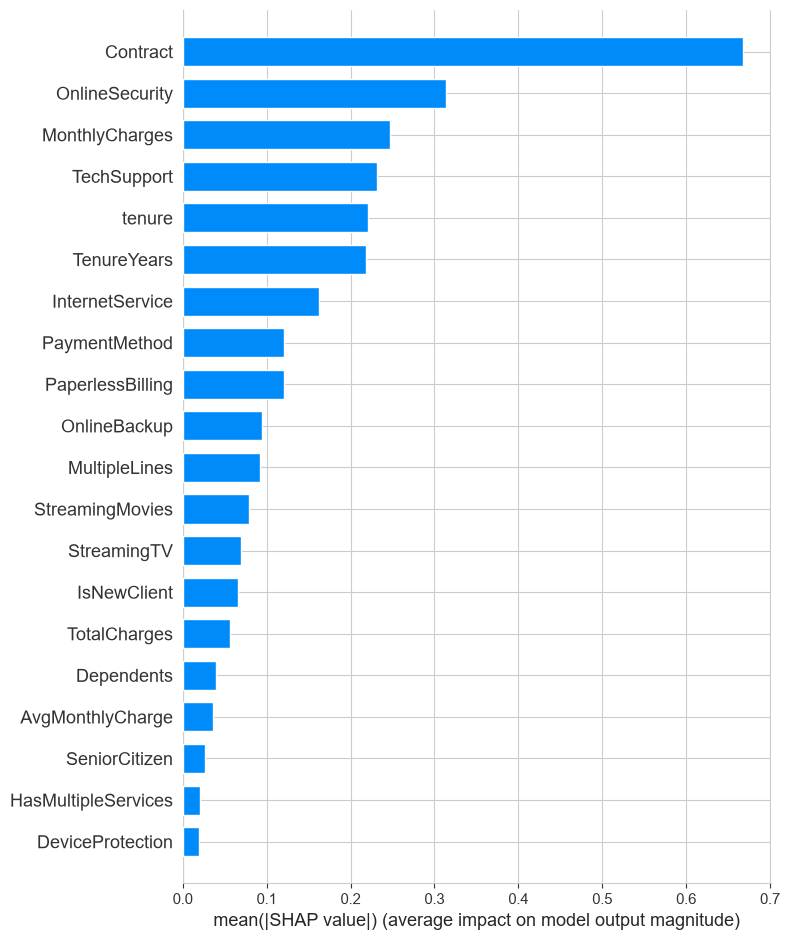

In [91]:
shap.summary_plot(shap_values_class1, X_test, plot_type="bar")

In [92]:
# Находим клиента с наибольшей вероятностью ухода
worst_idx = np.argmax(y_proba_best)
print(f"Клиент #{worst_idx}, вероятность ухода = {y_proba_best[worst_idx]:.4f}")

# waterfall
expl = shap.Explanation(
    values=shap_values_class1[worst_idx],
    base_values=(explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray))
                 else explainer.expected_value),
    data=X_test.iloc[worst_idx],
    feature_names=X_test.columns.tolist(),
)
shap.plots.waterfall(expl, show=False)
plt.gcf().set_size_inches(10, 8)
plt.tight_layout()
plt.savefig('examples/shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.close()

Клиент #1090, вероятность ухода = 0.9660


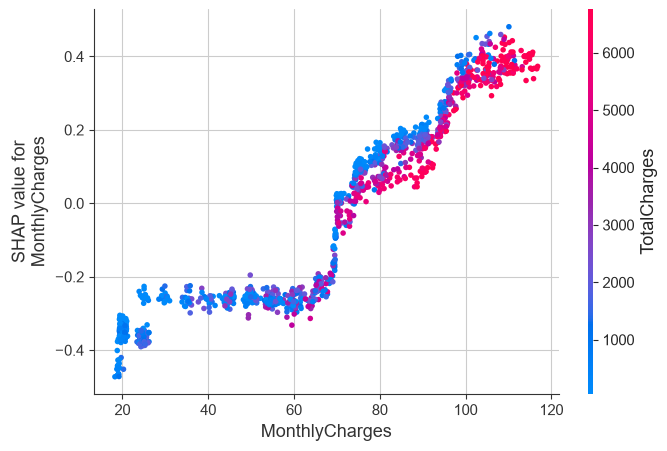

In [93]:
top_feature = importances.iloc[0]['Feature']
shap.dependence_plot(top_feature, shap_values_class1, X_test)


## SHAP-интерпретация

### Summary plot (глобальная важность)
- **Contract** — главный драйвер. `Month-to-month` (синие точки) резко повышает риск ухода, долгосрочные контракты — снижают.
- **OnlineSecurity / TechSupport** — наличие услуг (красные точки) сильно уменьшает отток.
- **MonthlyCharges** — высокие платежи увеличивают риск.
- **tenure / TenureYears** — новички уходят, долгосрочные клиенты лояльны.
- **InternetService (Fiber optic)** — повышает вероятность ухода.

### Waterfall plot (клиент с высоким риском, f(x) = 3.347)
Основные факторы риска для этого клиента:
1. **TenureYears = 0.083** (+0.56) — клиент с компанией меньше месяца.
2. **tenure = 1** (+0.54) — подтверждает критический период.
3. **Contract = 0 (Month-to-month)** (+0.33) — нет долгосрочных обязательств.
4. **MonthlyCharges = 95.1** (+0.31) — высокий чек.
5. **OnlineSecurity = 0** (+0.24) и **TechSupport = 0** (+0.22) — нет защитных услуг.

**Итог:** классический профиль «новый клиент на дорогом тарифе без допуслуг». Рекомендация бизнесу — предлагать таким клиентам долгосрочный контракт и бонусные сервисы.

## Сохранение модели и метаданных

In [94]:
joblib.dump(rf_model,   'models/rf_model.pkl')
joblib.dump(xgb_model,  'models/xgb_model.pkl')
joblib.dump(lgbm_model, 'models/lgbm_model.pkl')
joblib.dump(cat_model,  'models/cat_model.pkl')
joblib.dump(best_model, 'models/best_model.pkl')

# Scaler (обязательно по ТЗ)
joblib.dump(scaler, 'models/scaler.pkl')

# Label encoders (обязательно по ТЗ)
joblib.dump(label_encoders, 'models/label_encoders.pkl')

# Список признаков
with open('models/feature_cols.json', 'w', encoding='utf-8') as f:
    json.dump(feature_cols, f, ensure_ascii=False, indent=2)

# Метрики
metrics = {
    'random_forest': {k: float(v) for k, v in results[0].items() if k != 'Model'},
    'xgboost':       {k: float(v) for k, v in results[1].items() if k != 'Model'},
    'lightgbm':      {k: float(v) for k, v in results[2].items() if k != 'Model'},
    'catboost':      {k: float(v) for k, v in results[3].items() if k != 'Model'},
    'best_model': 'CatBoost (Optuna)',
    'best_roc_auc': float(study.best_value),
    'best_params':  study.best_params
}
with open('models/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)

print("✅ Все модели и метаданные сохранены")

✅ Все модели и метаданные сохранены


## Загрузка модели из репозитория

In [95]:
import requests
from io import BytesIO
import joblib

BASE_URL = "https://raw.githubusercontent.com/Sorokin2/ml-course-sorokin/main/module-3-churn"

# Загрузка модели
model_url = f"{BASE_URL}/models/best_model.pkl"
best_cat_loaded = joblib.load(BytesIO(requests.get(model_url).content))

# Загрузка признаков
features_url = f"{BASE_URL}/models/feature_cols.json"
feature_cols_loaded = requests.get(features_url).json()

print("✅ Модель загружена из репозитория")
print(f"✅ Загружено {len(feature_cols_loaded)} признаков")

✅ Модель загружена из репозитория
✅ Загружено 23 признаков


In [96]:
y_pred_loaded = best_cat_loaded.predict(X_test.iloc[:3])
y_pred_original = best_model.predict(X_test.iloc[:3])

print(f"Загруженная модель:  {y_pred_loaded}")
print(f"Исходная модель:     {y_pred_original}")
print(f"Совпадают: {np.array_equal(y_pred_loaded, y_pred_original)}")


Загруженная модель:  [0 1 0]
Исходная модель:     [0 1 0]
Совпадают: True


## Выводы

### Что получилось

- Обучены **4 ансамблевые модели**: RF, XGBoost, LightGBM, CatBoost — с компенсацией дисбаланса (`class_weight` / `scale_pos_weight` / `auto_class_weights='Balanced'`).
- По ROC-AUC на baseline лидировал **CatBoost (0.8409)** — его выбрали для тюнинга через Optuna.
- После **30 trials Optuna (5-fold CV)** ROC-AUC на test составил **0.8461**, прирост **+0.62%** к baseline (0.8409 → 0.8461).
- Метрики best_model (CatBoost + Optuna) на test:
  - Accuracy = 0.7410
  - Precision (Ушёл) = 0.5077
  - Recall (Ушёл) = 0.7968
  - F1 (Ушёл) = 0.6202
  - ROC-AUC = 0.8461
- Построены SHAP-графики (summary, bar, waterfall, dependence). Топ-драйверы по SHAP bar: **`MonthlyCharges`, `TotalCharges`, `AvgMonthlyCharge`, `tenure`, `PaymentMethod`**. По направлению влияния: короткий `tenure` и `Contract = Month-to-month` → резко повышают риск оттока.
- Модели + метаданные (включая `scaler.pkl` и `label_encoders.pkl`) сохранены в `models/`, загрузка из GitHub проверена (предсказания совпадают).

### Какие были трудности

- **Дисбаланс классов (73.5 / 26.5)** — пришлось использовать `class_weight='balanced'`, `scale_pos_weight=3`, `auto_class_weights='Balanced'`. Без этого Recall падал до ~0.3.
- **Пропуски в `TotalCharges`** (~0.2%, пустые строки) — заполнены медианой; `pd.to_numeric(errors='coerce')` обязателен.
- **Интерпретация категориальных признаков** после `LabelEncoder` — SHAP-графики показывают коды, а не названия категорий; для waterfall/dependence приходится сверяться с `label_encoders`.
- **`AvgMonthlyCharge` при `tenure=0`** даёт выброс (max = 1397) — формула `TotalCharges / (tenure + 1)`; для новых клиентов признак шумный.

### Возможные улучшения

1. **Stacking** из 4 моделей (RF + XGB + LGBM + Cat) с мета-моделью (LogisticRegression) — по заданию это +5 бонусных баллов.
2. **SMOTE / ADASYN** для балансировки вместо `class_weight` — проверить, даст ли прирост Recall/F1.
3. **Калибровка вероятностей** (`CalibratedClassifierCV`) — для корректной интерпретации `predict_proba` в бизнесе (например, при расчёте ожидаемых потерь).
4. **Feature interactions** — добавить `Contract × tenure`, `InternetService × MonthlyCharges` — деревья могут не выявить эти взаимодействия явно.
5. **Feature Store / версионирование** — сохранять `feature_cols.json` + `label_encoders.pkl` + `scaler.pkl` как единый артефакт (например, через `mlflow` или `dvc`).
6. **Порог классификации** — подобрать threshold на CV по F1/Recall (сейчас 0.5 по умолчанию), это может дать +2–3% F1.
7. **Бизнес-метрика** — оценить `expected_savings = TP × LTV - FP × cost_of_retention` и подобрать порог под неё.

## Список источников + Приложение

## Источники

1. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5-32.
2. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD '16*.
3. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.
4. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.
5. Lundberg, S., & Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.
6. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD '19*.

## Приложение

| Модель | Accuracy | Precision | Recall | F1 | ROC-AUC |
|--------|----------|-----------|--------|-----|---------|
| Random Forest | 0.7601 | 0.5346 | 0.7433 | 0.6219 | 0.8388 |
| XGBoost | 0.7608 | 0.5383 | 0.6952 | 0.6068 | 0.8285 |
| LightGBM | 0.7594 | 0.5332 | 0.7513 | 0.6238 | 0.8377 |
| CatBoost (baseline) | 0.7488 | 0.5187 | 0.7433 | 0.6110 | 0.8409 |
| **CatBoost + Optuna** | **0.7410** | **0.5077** | **0.7968** | **0.6202** | **0.8461** |


```txt
numpy==1.24.4
pandas==2.0.3
scipy==1.11.4
scikit-learn==1.3.2
xgboost==2.0.3
lightgbm==4.1.0
catboost==1.2.2
optuna==3.5.0
shap==0.44.1
matplotlib==3.8.2
seaborn==0.13.0
joblib==1.3.2
requests==2.31.0
jupyter==1.0.0
notebook==7.0.6
ipykernel==6.27.1
```